In [1]:
from astropy import units
from astropy.time import Time
from astropy.visualization import quantity_support

from matplotlib import pyplot

import numpy 

from src.selflensing.fitting import self_lensing_system_from_fit
from src.selflensing.generators import LightcurveGenerator, RVGenerator
from src.selflensing.models import SelfLensingSystem

from src.selflensing.gp import TESSGP

In [2]:
quantity_support()

<astropy.visualization.units.quantity_support.<locals>.MplQuantityConverter at 0x11cb53b60>

In [3]:
LENSING_METHOD = 'IntegratedWittMao'

In [4]:
(0.09 * units.AU).to(units.R_sun)

<Quantity 19.35289401 solRad>

In [5]:
sls = SelfLensingSystem(
    a=2 * units.AU,
    i=0.5*numpy.pi * units.rad,
    Macc=10*units.M_sun,
    Mcomp=1*units.M_sun,
    Rcomp=1*units.R_sun,
    e=0 * units.dimensionless_unscaled,
    d=438.1*units.kpc,
)
sls.porb, sls.tau_eff, sls.b, sls.b_max, sls.rE(), sls.i, sls.tau_eff

(<Quantity 311.49212956 d>,
 <Quantity 0.27460321 d>,
 <Quantity -9.83800846e-05>,
 Quantity(Array(6.2333426, dtype=float32), unit=''),
 Quantity(Array(1.3293606e+08, dtype=float32), unit='m'),
 Quantity(Array(1.5707964, dtype=float32), unit='rad'),
 <Quantity 0.27460321 d>)

In [6]:
start_time = Time("2025-01-01")
end_time = Time("2025-01-05")
peak_time = Time("2025-01-03")

In [7]:
lcg = LightcurveGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time, ev=True, db=True, sl=True, lensing_method=LENSING_METHOD, gp=TESSGP, bins=27*24*6)
rvg = RVGenerator(sls, start_time=start_time, end_time=end_time, peak_time=peak_time)

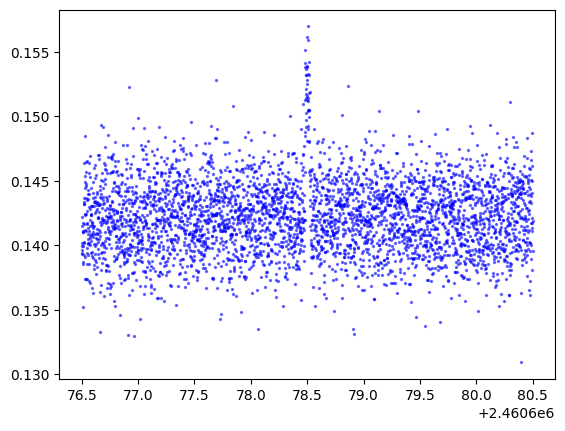

In [8]:
pyplot.scatter(lcg.times.jd, lcg.flux_array, s=2, alpha=0.5, c='blue')

In [9]:
# tgp = TESSGP(sls, lcg.time_offsets, lcg.flux_array)
# tgp.p0.shape

In [10]:
# gp_theta, sampler = tgp.fit()
# gp_theta

In [11]:
# max(sampler.get_log_prob(flat=True))

In [12]:
# import jax

# from src.selflensing.gp import LensingGP as lgp
# mag_lc = lgp.build_model_additive(
#     gp_theta, 
#     5, 
#     lgp.make_kernel_fn('GS'), 
#     lcg.time_offsets, 
#     include_lens_mean=0, 
#     noise_measure=tgp.noise_measure,
# )
# mag_samp = mag_lc.sample(jax.random.PRNGKey(tgp.seed))

# plt=pyplot
# # Plot the noise-only model
# plt.figure()
# # plt.errorbar(TESS_times_27/(24 * 60 * 60), noise_samp, yerr=noise_measure, ls = 'none', color = 'grey')
# plt.plot(lcg.times.jd, mag_samp, label='Noise-only model', marker ='o', markersize=2, linestyle = 'None', color='black', alpha=0.5)
# plt.xlabel('Time [days]')
# plt.ylabel('Flux')
# plt.show()

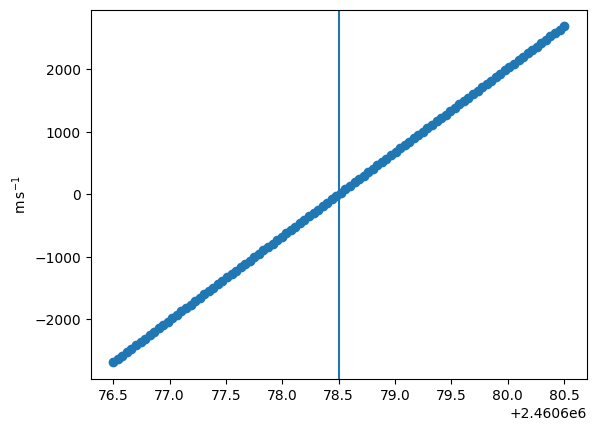

In [13]:
pyplot.scatter(rvg.times.jd, rvg.rv)
pyplot.axvline(peak_time.jd)

## Orbital period detection

In [14]:
# import numpy
# peak_mag = numpy.max(lcg.timeseries['flux']) / numpy.median(lcg.timeseries['flux'])
# min_mag = peak_mag * 0.999
# max_mag = peak_mag * 1.001
# min_mag, peak_mag, max_mag

In [15]:
# non_detection_times = [t for t in lcg.time_offsets if t not in lcg.peak_time_offsets]

In [16]:
# from src.selflensing.porb import estimate_porb

# p = estimate_porb(sls.tau_eff, min_mag, max_mag, sls.Rcomp)
# p

In [17]:
# from astropy import units
# bin_starts = units.Quantity(p[0])
# bin_ends = units.Quantity(p[1])
# bin_counts = numpy.array(p[2])
# total_count = sum(bin_counts)

# bin_widths = bin_ends - bin_starts
# bin_centres = (bin_starts + bin_ends) / 2
# n_density = (bin_counts/total_count) / bin_widths.to(units.year).value

# pyplot.plot(bin_centres.to(units.year).value, n_density)
# pyplot.xscale('log')
# pyplot.axvline(sls.porb.to(units.year).value)

In [18]:
# pyplot.plot(bin_centres.to(units.year).value, n_density)
# pyplot.xscale('log')
# pyplot.yscale('log')
# pyplot.axvline(sls.porb.to(units.year).value)

In [19]:
# from src.selflensing.porb import LENS_MASS_DIST
# mass_bin_width = LENS_MASS_DIST[0, 1] - LENS_MASS_DIST[0, 0]
# pyplot.plot(LENS_MASS_DIST[0,:], LENS_MASS_DIST[1,:] / mass_bin_width)
# pyplot.axvline(sls.Macc.to(units.M_sun).value)

## Fitting

In [20]:
sls_fit, sampler = self_lensing_system_from_fit(
    rv_times=rvg.times,
    observed_rv=rvg.rv,
    observed_rv_err=rvg.rv/10,
    lc_times=lcg.times,
    observed_lc=lcg.flux_array,
    observed_lc_err=1 * lcg.units,
    gp_model=TESSGP,
    peak_time=peak_time,
    Mcomp=sls.Mcomp,
    Rcomp=sls.Rcomp,
    Teff=sls.Teff,
    tau_eff=sls.tau_eff,
    # period_min=350 * units.day,
    # detect_periods=True,
    nsteps=5000,
    # nwalkers=20,
    burn=10,
    lensing_method=LENSING_METHOD,
)
lcg_fit = LightcurveGenerator(sls_fit, start_time=start_time, end_time=end_time, peak_time=peak_time, lensing_method=LENSING_METHOD)
rvg_fit = RVGenerator(sls_fit, start_time=start_time, end_time=end_time, peak_time=peak_time)

/Users/adam/Library/Caches/pypoetry/virtualenvs/selflensing-OJwetTlj-py3.13/lib/python3.13/site-packages/astropy/units/quantity.py:648: RuntimeWarning: invalid value encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


<class 'quax._core._QuaxTracer'>
emcee: Exception while calling your likelihood function:
  params: [[1.00000000e-02 1.51621643e+00 2.63019224e+01 9.86978467e-01
  4.55043504e+00]
 [1.10520985e-02 1.50290639e+00 4.40979722e+01 7.47027489e-03
  1.39218155e+00]
 [1.22148882e-02 1.49314420e+00 3.59733169e+00 6.41334512e-01
  3.59635304e+00]
 [1.35000147e-02 1.41826128e+00 2.17649938e+01 1.80001241e-01
  4.82507269e+00]
 [1.49203493e-02 1.44181288e+00 4.76573314e+01 2.12455635e-01
  4.72758850e+00]
 [1.64901170e-02 1.42213293e+00 2.51943115e+00 4.15821226e-01
  7.24279638e-01]
 [1.82250398e-02 1.46714917e+00 1.18953431e+01 6.59433829e-01
  4.01421738e+00]
 [2.01424935e-02 1.52416478e+00 1.08465035e+01 7.89552602e-01
  1.80004228e+00]
 [2.22616822e-02 1.44597961e+00 4.76719416e+01 3.36155159e-01
  6.27924782e+00]
 [2.46038305e-02 1.53786689e+00 4.31011646e+01 4.51928414e-01
  1.75421086e+00]
 [2.71923959e-02 1.42942075e+00 4.70064027e+01 6.93377376e-01
  2.25100885e+00]
 [3.00533038e-02 1.5

Traceback (most recent call last):
  File "/Users/adam/Library/Caches/pypoetry/virtualenvs/selflensing-OJwetTlj-py3.13/lib/python3.13/site-packages/emcee/ensemble.py", line 640, in __call__
    return self.f(x, *self.args, **self.kwargs)
           ~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/adam/Library/Caches/pypoetry/virtualenvs/selflensing-OJwetTlj-py3.13/lib/python3.13/site-packages/jax/_src/traceback_util.py", line 195, in reraise_with_filtered_traceback
    return fun(*args, **kwargs)
  File "/Users/adam/Library/Caches/pypoetry/virtualenvs/selflensing-OJwetTlj-py3.13/lib/python3.13/site-packages/jax/_src/pjit.py", line 264, in cache_miss
    executable, pgle_profiler, const_args) = _python_pjit_helper(
                                             ~~~~~~~~~~~~~~~~~~~^
        fun, jit_info, *args, **kwargs)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/adam/Library/Caches/pypoetry/virtualenvs/selflensing-OJwetTlj-py3.13/lib/python3.13/site-packages/jax/_src/pjit.

TypeError: Cannot convert `Quantity['mass'](1., unit='solMass')` to `jax.Array`.

In [ ]:
sampler.get_log_prob(flat=True)

array([-inf, -inf, -inf, ..., -inf, -inf, -inf], shape=(500000,))

In [ ]:
sls_fit.a, sls_fit.Macc

(<Quantity -3.51935627 AU>, <Quantity 6.7501399 solMass>)

/Users/adam/Library/Caches/pypoetry/virtualenvs/selflensing-OJwetTlj-py3.13/lib/python3.13/site-packages/astropy/units/quantity.py:659: RuntimeWarning: invalid value encountered in sqrt
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)

thread '<unnamed>' panicked at /Users/runner/.cargo/registry/src/index.crates.io-1949cf8c6b5b557f/ellip-0.3.3/src/legendre/ellipe.rs:85:31:
called `Option::unwrap()` on a `None` value
note: run with `RUST_BACKTRACE=1` environment variable to display a backtrace

thread '<unnamed>' panicked at /Users/runner/.cargo/registry/src/index.crates.io-1949cf8c6b5b557f/ellip-0.3.3/src/legendre/ellipe.rs:85:31:
called `Option::unwrap()` on a `None` value

thread '<unnamed>' panicked at /Users/runner/.cargo/registry/src/index.crates.io-1949cf8c6b5b557f/ellip-0.3.3/src/legendre/ellipe.rs:85:31:
called `Option::unwrap()` on a `None` value

thread '<unnamed>' panicked at /Users/runner/.cargo/registry/src/index.crates.io-1949cf8c6b5b557f/ellip-0.3.

PanicException: called `Option::unwrap()` on a `None` value

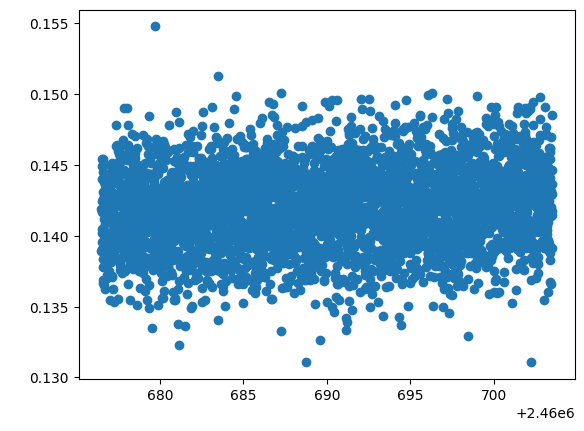

In [ ]:
pyplot.scatter(lcg.times.jd, lcg.flux_array)
pyplot.plot(lcg_fit.times.jd, lcg_fit.flux_array, c='red')
pyplot.axvline(peak_time.jd)

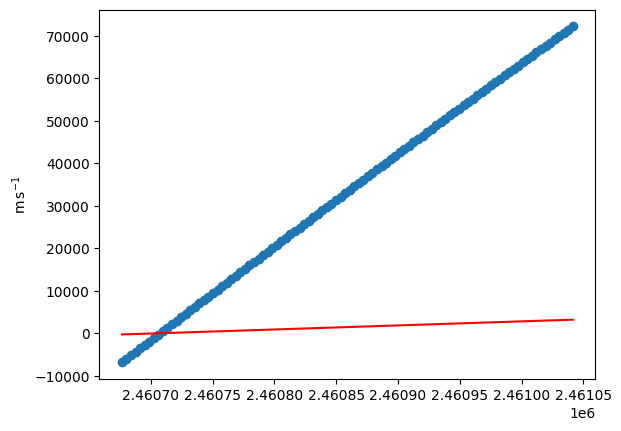

In [ ]:
pyplot.scatter(rvg.times.jd, rvg.rv)
pyplot.plot(rvg_fit.times.jd, rvg_fit.rv, c='red')

Text(0.5, 0, 'step number')

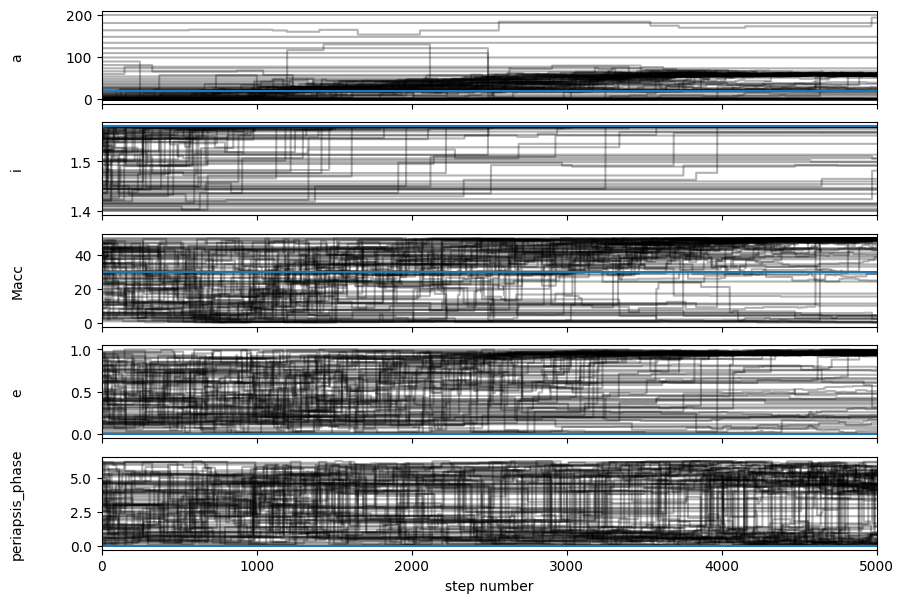

In [ ]:
truths=[sls.a.value, sls.i.value, sls.Macc.value, sls.e.value, sls.periapsis_phase.value]

from matplotlib import pyplot as plt
labels = ["a", "i", "Macc", 'e', 'periapsis_phase']
fig, axes = plt.subplots(len(labels), figsize=(10, 7), sharex=True)
samples = sampler.get_chain()#discard=100)
flat_samples = sampler.get_chain(flat=True)
for i in range(len(labels)):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.axhline(truths[i])
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")

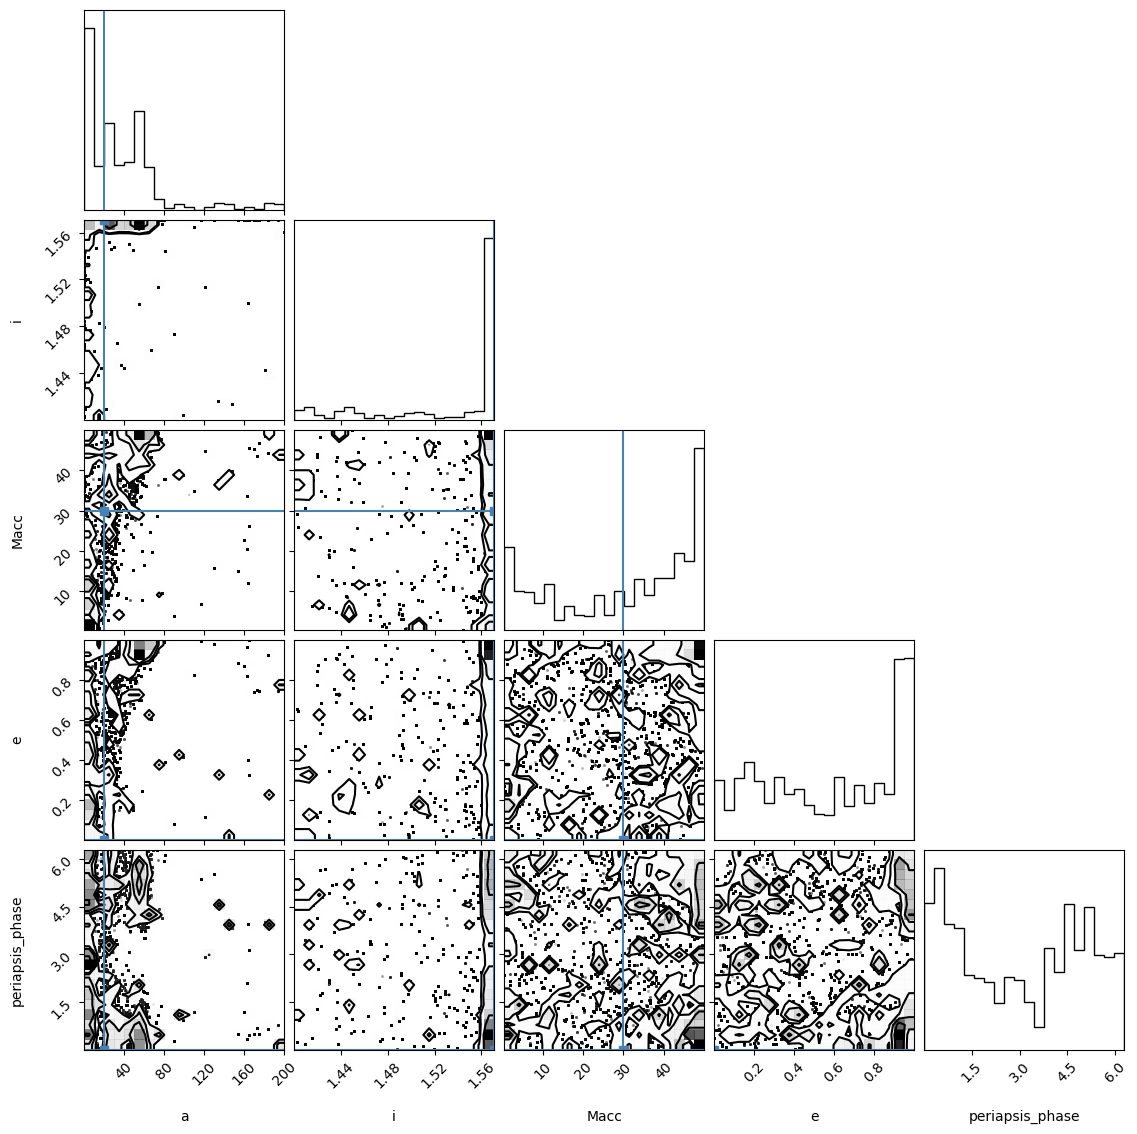

In [ ]:
import corner

fig = corner.corner(
    flat_samples, labels=labels, truths=truths
)